# ABC Tech — ITSM Machine Learning Capstone (PRCL-0012)

**Client:** ABC Tech | **Category:** IT Service Management (ITSM) | **Project Ref:** PM-PR-0012

## Business Case

ABC Tech is a mid-size IT-enabled services organization handling 22–25k IT incidents/tickets annually under a mature ITIL framework (incident, problem, change, and configuration management). A recent audit found that further process-only improvements have limited ROI, and a customer survey rated incident management poorly. Management identified four areas where Machine Learning could improve ITSM outcomes:

1. **Predict high-priority tickets** — flag Priority 1/2 tickets early so preventive action can be taken.
2. **Forecast incident volume** — quarterly/annual forecasts for resourcing and technology planning.
3. **Auto-tag tickets** — assign the right category/priority automatically to reduce reassignment delays.
4. **Predict RFC-related risk** — anticipate incidents likely to require a Request for Change (RFC).

## Scope Note

During EDA, two of the four goals as originally stated could not be built exactly as specified, because the required fields do not exist in the underlying dataset:

- No department/assignment-group field exists anywhere in the schema, so **Task 3** is redefined as auto-tagging the **CI Category** (`CI_Cat`) rather than department.
- No RFC success/failure or misconfiguration outcome field exists, so **Task 4** is redefined as predicting **whether an incident becomes linked to a change request at all** (`No_of_Related_Changes > 0`), rather than predicting RFC failure specifically.

Both substitutions are documented at the point they were made, with the evidence that justified them.

## 1. Data Loading

Data lives in a MySQL database rather than a flat file. We connect read-only, discover the table name, and pull the full table into a DataFrame.

> **Running this notebook:** set the `ITSM_DB_HOST`, `ITSM_DB_USER` and `ITSM_DB_PASSWORD` environment variables before launching Jupyter (see `.env.example` in the repo root). The database was provided by the course (DataMites) and is not included in this repository.

In [1]:
import os
import pandas as pd
from sqlalchemy import create_engine
from urllib.parse import quote_plus

# Credentials are read from environment variables (see .env.example) - never hard-code them.
host = os.environ["ITSM_DB_HOST"]
port = int(os.environ.get("ITSM_DB_PORT", 3306))
user = os.environ["ITSM_DB_USER"]
password = quote_plus(os.environ["ITSM_DB_PASSWORD"])  # encodes special chars (@, !, $) safely
database = os.environ.get("ITSM_DB_NAME", "project_itsm")

engine = create_engine(f"mysql+pymysql://{user}:{password}@{host}:{port}/{database}")

tables = pd.read_sql("SHOW TABLES;", engine)
print(tables)

  Tables_in_project_itsm
0           dataset_list


In [2]:
df = pd.read_sql("SELECT * FROM dataset_list;", engine)
print(df.shape)
df.head()

(46606, 25)


,CI_Name,CI_Cat,CI_Subcat,WBS,Incident_ID,Status,Impact,Urgency,Priority,number_cnt,...,Reopen_Time,Resolved_Time,Close_Time,Handle_Time_hrs,Closure_Code,No_of_Related_Interactions,Related_Interaction,No_of_Related_Incidents,No_of_Related_Changes,Related_Change
0,SUB000508,subapplication,Web Based Application,WBS000162,IM0000004,Closed,4,4,4,0.601292279,...,,04-11-2013 13:50,04-11-2013 13:51,"3,87,16,91,111",Other,1,SD0000007,2,,
1,WBA000124,application,Web Based Application,WBS000088,IM0000005,Closed,3,3,3,0.415049969,...,02-12-2013 12:31,02-12-2013 12:36,02-12-2013 12:36,"4,35,47,86,389",Software,1,SD0000011,1,,
2,DTA000024,application,Desktop Application,WBS000092,IM0000006,Closed,NS,3,NA,0.517551335,...,,13-01-2014 15:12,13-01-2014 15:13,"4,84,31,19,444",No error - works as designed,1,SD0000017,,,
3,WBA000124,application,Web Based Application,WBS000088,IM0000011,Closed,4,4,4,0.642927218,...,,14-11-2013 09:31,14-11-2013 09:31,"4,32,18,33,333",Operator error,1,SD0000025,,,
4,WBA000124,application,Web Based Application,WBS000088,IM0000012,Closed,4,4,4,0.345258343,...,,08-11-2013 13:55,08-11-2013 13:55,"3,38,39,03,333",Other,1,SD0000029,,,


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46606 entries, 0 to 46605
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   CI_Name                     46606 non-null  object
 1   CI_Cat                      46606 non-null  object
 2   CI_Subcat                   46606 non-null  object
 3   WBS                         46606 non-null  object
 4   Incident_ID                 46606 non-null  object
 5   Status                      46606 non-null  object
 6   Impact                      46606 non-null  object
 7   Urgency                     46606 non-null  object
 8   Priority                    46606 non-null  object
 9   number_cnt                  46606 non-null  object
 10  Category                    46606 non-null  object
 11  KB_number                   46606 non-null  object
 12  Alert_Status                46606 non-null  object
 13  No_of_Reassignments         46606 non-null  ob

## 2. Data Cleaning

`.info()` above shows every column as non-null and `object` dtype — that's misleading on both counts:

- Placeholder strings like `"NS"` and `"NA"` are hiding real missingness (pandas only recognizes actual `NaN` as missing).
- Numeric and datetime columns were loaded as text, so no arithmetic or comparisons work on them yet.

We fix both issues before doing anything else.

In [4]:
import numpy as np

# Replace known placeholder strings with actual NaN
placeholder_values = ['NS', 'NA', '', ' ', 'nan', 'NaN', 'None']
df = df.replace(placeholder_values, np.nan)

# Check missingness now that it's actually visible
print(df.isnull().sum())

CI_Name                           0
CI_Cat                          111
CI_Subcat                       111
WBS                               0
Incident_ID                       0
Status                            0
Impact                         1380
Urgency                           0
Priority                       1380
number_cnt                        0
Category                          0
KB_number                         0
Alert_Status                      0
No_of_Reassignments               1
Open_Time                         0
Reopen_Time                   44322
Resolved_Time                  1780
Close_Time                        0
Handle_Time_hrs                   1
Closure_Code                    460
No_of_Related_Interactions      114
Related_Interaction               0
No_of_Related_Incidents       45384
No_of_Related_Changes         46046
Related_Change                46046
dtype: int64


In [5]:
# Numeric columns that were incorrectly loaded as text
numeric_cols = ['Impact', 'Urgency', 'Priority', 'No_of_Reassignments',
                 'No_of_Related_Interactions', 'No_of_Related_Incidents',
                 'No_of_Related_Changes']

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Datetime columns
datetime_cols = ['Open_Time', 'Reopen_Time', 'Resolved_Time', 'Close_Time']

for col in datetime_cols:
    df[col] = pd.to_datetime(df[col], format='%d-%m-%Y %H:%M', errors='coerce')

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46606 entries, 0 to 46605
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   CI_Name                     46606 non-null  object        
 1   CI_Cat                      46495 non-null  object        
 2   CI_Subcat                   46495 non-null  object        
 3   WBS                         46606 non-null  object        
 4   Incident_ID                 46606 non-null  object        
 5   Status                      46606 non-null  object        
 6   Impact                      45226 non-null  float64       
 7   Urgency                     46605 non-null  float64       
 8   Priority                    45226 non-null  float64       
 9   number_cnt                  46606 non-null  object        
 10  Category                    46606 non-null  object        
 11  KB_number                   46606 non-null  object    

In [6]:
df.isnull().sum()

CI_Name                           0
CI_Cat                          111
CI_Subcat                       111
WBS                               0
Incident_ID                       0
Status                            0
Impact                         1380
Urgency                           1
Priority                       1380
number_cnt                        0
Category                          0
KB_number                         0
Alert_Status                      0
No_of_Reassignments               1
Open_Time                         0
Reopen_Time                   44322
Resolved_Time                  1780
Close_Time                        0
Handle_Time_hrs                   1
Closure_Code                    460
No_of_Related_Interactions      114
Related_Interaction               0
No_of_Related_Incidents       45384
No_of_Related_Changes         46046
Related_Change                46046
dtype: int64

### Investigating `Handle_Time_hrs`

Converting numeric columns revealed a corrupted field: values like `"3,87,16,91,111"` are not valid hours. Stripping the commas and reformatting the raw digit string using Indian-locale thousands-grouping reproduces the exact same string — meaning the decimal point was dropped somewhere in the original export pipeline and the fused digit sequence was then run through locale-based number formatting. The original decimal position is unrecoverable from the string alone, so this field is treated as corrupted beyond safe repair and dropped. It is replaced with a derived version computed directly from two trustworthy timestamp columns.

In [7]:
# Look at raw values before assuming what they mean
print(df['Handle_Time_hrs'].head(20).tolist())
print(df['Handle_Time_hrs'].astype(str).str.len().describe())

['3,87,16,91,111', '4,35,47,86,389', '4,84,31,19,444', '4,32,18,33,333', '3,38,39,03,333', '3,38,34,36,944', '3,70,31,91,389', '3,29,46,24,167', '0,862777778', '3,21,15,26,944', '3,06,74,49,167', '1,32,26,19,167', '1,13,24,28,333', '6,67,54,16,667', '3,11,43,58,056', '2,83,79,50,556', '1,22,37,48,333', '3,79,27,77,778', '2,62,67,33,889', '9,31,78,08,333']
count    46606.000000
mean        12.322426
std          2.797987
min          1.000000
25%         11.000000
50%         14.000000
75%         14.000000
max         14.000000
Name: Handle_Time_hrs, dtype: float64


In [8]:
df['Handle_Time_derived_hrs'] = (df['Close_Time'] - df['Open_Time']).dt.total_seconds() / 3600
print(df['Handle_Time_derived_hrs'].describe())

count    46606.000000
mean       123.132951
std        452.794319
min          0.000000
25%          1.266667
50%         18.400000
75%         95.083333
max      15722.616667
Name: Handle_Time_derived_hrs, dtype: float64


### Verifying the "blank = zero" hypothesis for count fields

`No_of_Related_Changes` and `No_of_Related_Incidents` are ~98–99% "missing" after the placeholder fix. Rather than assume this means "unknown" (which would force dropping almost the entire dataset for Task 4), we check what the *non-null* values actually look like — small counts like 1, 2, 3, 9 support "blank means zero occurrences," not "value unknown."

In [9]:
# Verify the hypothesis before committing to it: what do the NON-null values look like?
print(df['No_of_Related_Changes'].dropna().value_counts())
print(df['No_of_Related_Incidents'].dropna().value_counts())

No_of_Related_Changes
1.0    536
2.0     21
3.0      2
9.0      1
Name: count, dtype: int64
No_of_Related_Incidents
1.0     1057
2.0       74
3.0       20
4.0       13
5.0        8
6.0        8
9.0        6
8.0        5
7.0        4
12.0       4
11.0       4
16.0       3
17.0       3
10.0       2
24.0       2
23.0       1
14.0       1
25.0       1
54.0       1
26.0       1
21.0       1
63.0       1
13.0       1
15.0       1
Name: count, dtype: int64


In [10]:
# Drop the unrecoverable field, keep the derived one
df = df.drop(columns=['Handle_Time_hrs'])

In [11]:
# Count fields: blank almost certainly means "0 occurrences", not "unknown"
# (business case describes these as counts, and 97-99% blank rate matches
# "most tickets simply have zero related incidents/changes")
count_cols = ['No_of_Related_Changes', 'No_of_Related_Incidents', 'No_of_Related_Interactions']
for col in count_cols:
    df[col] = df[col].fillna(0)

# Timestamp: missing genuinely means "never reopened" — convert to a flag, don't fake a date
df['was_reopened'] = df['Reopen_Time'].notna().astype(int)

# Categorical, small missingness (~0.2%) — impute as explicit "Unknown" rather than drop rows
df['CI_Cat'] = df['CI_Cat'].fillna('Unknown')
df['CI_Subcat'] = df['CI_Subcat'].fillna('Unknown')
df['Closure_Code'] = df['Closure_Code'].fillna('Unknown')

# Impact/Priority genuinely missing (~3%) — these are your Task 1 target and a
# leakage-risk feature, so for MODELING you'll drop rows missing Priority later.
# Don't impute a target variable — that would be inventing labels.

# Now create the derived targets/features
df['has_change_request'] = (df['No_of_Related_Changes'] > 0).astype(int)
df['Open_Month'] = df['Open_Time'].dt.to_period('M')
df['Open_Quarter'] = df['Open_Time'].dt.to_period('Q')

print(df['has_change_request'].value_counts(normalize=True))
print(df.isnull().sum())

has_change_request
0    0.987984
1    0.012016
Name: proportion, dtype: float64
CI_Name                           0
CI_Cat                            0
CI_Subcat                         0
WBS                               0
Incident_ID                       0
Status                            0
Impact                         1380
Urgency                           1
Priority                       1380
number_cnt                        0
Category                          0
KB_number                         0
Alert_Status                      0
No_of_Reassignments               1
Open_Time                         0
Reopen_Time                   44322
Resolved_Time                  1780
Close_Time                        0
Closure_Code                      0
No_of_Related_Interactions        0
Related_Interaction               0
No_of_Related_Incidents           0
No_of_Related_Changes             0
Related_Change                46046
Handle_Time_derived_hrs           0
has_change_request  

## 3. Exploratory Data Analysis

Quick look across the four target areas: Priority distribution (Task 1), incident volume over time (Task 2), CI category distribution (Task 3), and a first check of whether CI category correlates with priority (candidate feature for Tasks 1 & 3).

Priority
4.0    22717
5.0    16486
3.0     5323
NaN     1380
2.0      697
1.0        3
Name: count, dtype: int64


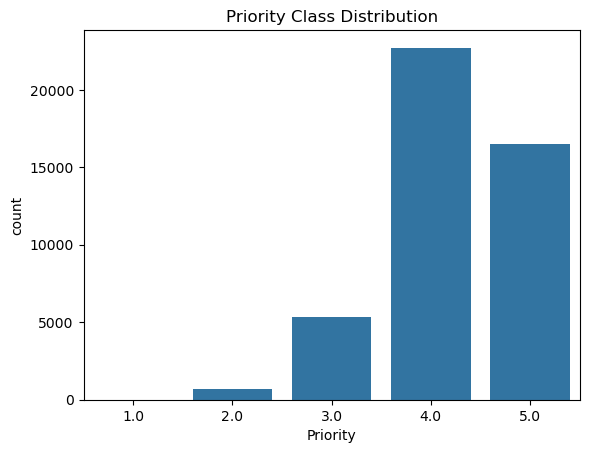

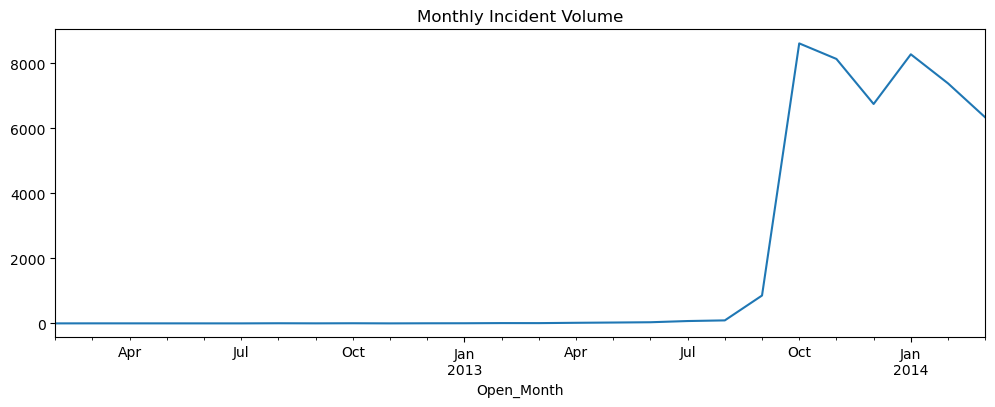

CI_Cat
application             32900
subapplication           7782
computer                 3643
storage                   703
hardware                  442
software                  333
database                  214
displaydevice             212
officeelectronics         152
Unknown                   111
networkcomponents         107
applicationcomponent        5
Phone                       2
Name: count, dtype: int64


Priority,1.0,2.0,3.0,4.0,5.0
CI_Cat,,,,,
Phone,0.000000,0.500000,0.500000,0.000000,0.000000
Unknown,0.000000,0.074074,0.120370,0.259259,0.546296
application,0.000031,0.006086,0.126016,0.485240,0.382627
applicationcomponent,0.000000,0.000000,0.750000,0.250000,0.000000
computer,0.000000,0.119921,0.104966,0.206546,0.568567
database,0.000000,0.000000,0.857143,0.095238,0.047619
displaydevice,0.000000,0.000000,0.004717,0.948113,0.047170
hardware,0.000000,0.014778,0.352217,0.194581,0.438424
networkcomponents,0.000000,0.222222,0.343434,0.313131,0.121212


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- Task 1: Priority distribution ---
print(df['Priority'].value_counts(dropna=False))
sns.countplot(data=df, x='Priority')
plt.title('Priority Class Distribution')
plt.show()

# --- Task 2: Incident volume over time ---
monthly_counts = df.groupby('Open_Month').size()
monthly_counts.plot(kind='line', figsize=(12,4), title='Monthly Incident Volume')
plt.show()

# --- Task 3: CI_Cat distribution ---
print(df['CI_Cat'].value_counts())

# --- Task 4: already confirmed above (98.8/1.2 split) ---

# Cross-check: does CI_Cat or Category correlate with Priority? (candidate features)
pd.crosstab(df['CI_Cat'], df['Priority'], normalize='index')

### Handling the near-empty Priority class

Priority 1.0 has only 3 records in the entire dataset — far too few for any model to learn from or be evaluated on reliably. Rather than drop these 3 tickets, they are merged into Priority 2.0 (both represent the top-urgency band), producing a workable 4-class target. This is documented as a deliberate simplification, not an oversight.

In [13]:
# Merge Priority 1 into 2 (creates a workable "Critical/High" tier), document why in the report
df['Priority_grouped'] = df['Priority'].replace({1.0: 2.0})
print(df['Priority_grouped'].value_counts())

Priority_grouped
4.0    22717
5.0    16486
3.0     5323
2.0      700
Name: count, dtype: int64


### Data collection ramp-up artifact

The monthly volume trend looked suspicious — checking the full monthly breakdown confirms incident volume was near-zero from Feb 2012 through Aug 2013 (a pilot/test period), then jumped roughly 10x within two months. Feeding this step-change into a forecasting model would teach it a fake "explosive growth" trend that isn't real business behavior. Task 2 forecasting is restricted to the stable window (Oct 2013 – Mar 2014) at **weekly** granularity — monthly leaves too few points (6) to model anything, while weekly gives ~26 usable points.

In [14]:
monthly_counts = df.groupby('Open_Month').size()
print(monthly_counts)

Open_Month
2012-02       1
2012-03       2
2012-07       1
2012-08       5
2012-09       2
2012-10       5
2012-11       1
2012-12       4
2013-01       5
2013-02      10
2013-03       9
2013-04      19
2013-05      27
2013-06      36
2013-07      73
2013-08      93
2013-09     857
2013-10    8606
2013-11    8128
2013-12    6743
2014-01    8270
2014-02    7377
2014-03    6332
Freq: M, dtype: int64


Open_Time
2013-09-08      49
2013-09-15      87
2013-09-22     108
2013-09-29     394
2013-10-06    1881
2013-10-13    1948
2013-10-20    1868
2013-10-27    1657
2013-11-03    1791
2013-11-10    2033
2013-11-17    1801
2013-11-24    2101
2013-12-01    1879
2013-12-08    1781
2013-12-15    1766
2013-12-22    1752
2013-12-29     882
2014-01-05    1185
2014-01-12    1893
2014-01-19    1698
2014-01-26    1959
2014-02-02    2098
2014-02-09    2111
2014-02-16    1749
2014-02-23    1867
2014-03-02    1656
2014-03-09    1540
2014-03-16    1627
2014-03-23    1514
2014-03-30    1421
2014-04-06     217
Freq: W-SUN, dtype: int64


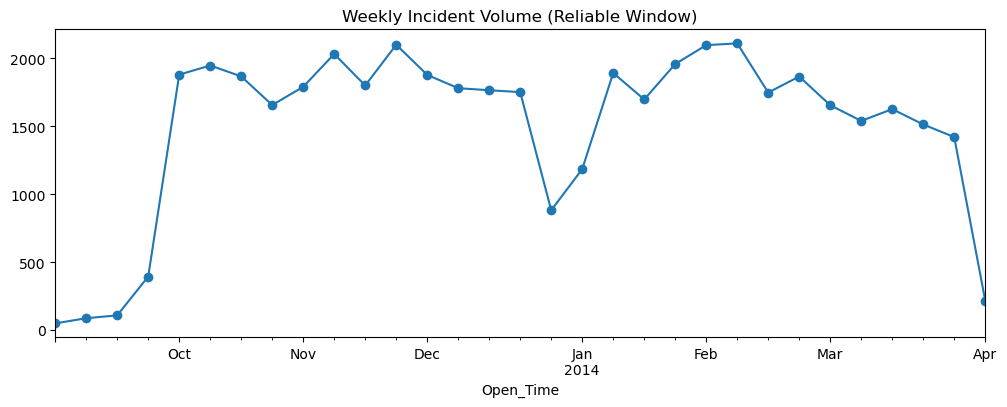

In [15]:
# Restrict to the reliable window only
df_reliable = df[df['Open_Time'] >= '2013-09-01'].copy()

# Use WEEKLY granularity instead of monthly — turns 6 months into ~26 data points
# instead of 6, giving the model something to actually learn from
weekly_counts = df_reliable.groupby(pd.Grouper(key='Open_Time', freq='W')).size()
print(weekly_counts)

weekly_counts.plot(kind='line', figsize=(12,4), title='Weekly Incident Volume (Reliable Window)', marker='o')
plt.show()

In [16]:
# Final modeling window: exclude ramp-up and partial final week
ts_data = weekly_counts['2013-10-06':'2014-03-30']

# Add a holiday flag rather than deleting the dip — it's real signal, not an error
ts_df = ts_data.reset_index()
ts_df.columns = ['week', 'incident_count']
ts_df['is_holiday_week'] = ts_df['week'].isin(['2013-12-29', '2014-01-05'])

C:\Users\Admin\AppData\Local\Temp\ipykernel_25444\3987381227.py:7: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  ts_df['is_holiday_week'] = ts_df['week'].isin(['2013-12-29', '2014-01-05'])


## 4. Task 1 — Priority Prediction

**Goal:** predict a ticket's priority level using information available at/near ticket creation.

**Leakage check first:** `Priority` is derived directly from `Impact × Urgency` via a fixed matrix in the business case document (confirmed later by crosstab — no combination hits anything but the matrix's prescribed value). Using Impact/Urgency as features would let the model "predict" priority by table lookup rather than learning anything real, so **both are excluded from the feature set**.

In [17]:
# Drop rows where the target itself is missing — can't train on invented labels
task1_df = df.dropna(subset=['Priority_grouped']).copy()
print(task1_df.shape)  # should be 46606 - 1380 = 45226

# Candidate features — deliberately excluding Impact and Urgency
feature_cols = ['CI_Cat', 'CI_Subcat', 'Category', 'WBS', 
                 'No_of_Reassignments', 'No_of_Related_Interactions', 
                 'No_of_Related_Incidents', 'No_of_Related_Changes',
                 'was_reopened', 'Handle_Time_derived_hrs', 'Alert_Status']

X = task1_df[feature_cols].copy()
y = task1_df['Priority_grouped']

(45226, 30)


In [18]:
# Check cardinality before committing WBS as a feature
print(task1_df['WBS'].nunique(), 'unique WBS values out of', len(task1_df), 'rows')
print(task1_df['CI_Cat'].nunique())
print(task1_df['Category'].nunique())

273 unique WBS values out of 45226 rows
13
4


In [19]:
# Check how concentrated WBS actually is — are a few codes doing most of the work?
wbs_counts = task1_df['WBS'].value_counts()
print(wbs_counts.head(20))
print(f"Top 20 WBS codes cover {wbs_counts.head(20).sum() / len(task1_df):.1%} of all tickets")

WBS
WBS000073    13292
WBS000091     2439
WBS000263     2277
WBS000072     2190
WBS000271     1182
WBS000095     1099
WBS000152     1074
WBS000318     1062
WBS000094      859
WBS000146      825
WBS000223      798
WBS000092      749
WBS000128      745
WBS000088      611
WBS000099      608
WBS000228      599
WBS000292      570
WBS000089      566
WBS000296      563
WBS000162      477
Name: count, dtype: int64
Top 20 WBS codes cover 72.0% of all tickets


In [20]:
# 1. Bucket rare WBS codes
top_wbs = wbs_counts.head(20).index
task1_df['WBS_grouped'] = task1_df['WBS'].where(task1_df['WBS'].isin(top_wbs), 'Other')

# 2. Encode
categorical_cols = ['CI_Cat', 'CI_Subcat', 'Category', 'WBS_grouped', 'Alert_Status']
numeric_cols = ['No_of_Reassignments', 'No_of_Related_Interactions',
                'No_of_Related_Incidents', 'No_of_Related_Changes']

X_encoded = pd.get_dummies(task1_df[categorical_cols + numeric_cols], 
                             columns=categorical_cols, drop_first=True)

# 3. Time-aware split
task1_df_sorted = task1_df.sort_values('Open_Time')
split_idx = int(len(task1_df_sorted) * 0.8)
train_idx = task1_df_sorted.index[:split_idx]
test_idx = task1_df_sorted.index[split_idx:]

X_train, X_test = X_encoded.loc[train_idx], X_encoded.loc[test_idx]
y_train, y_test = y.loc[train_idx], y.loc[test_idx]

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Train dates: {task1_df_sorted.loc[train_idx, 'Open_Time'].min()} to {task1_df_sorted.loc[train_idx, 'Open_Time'].max()}")
print(f"Test dates: {task1_df_sorted.loc[test_idx, 'Open_Time'].min()} to {task1_df_sorted.loc[test_idx, 'Open_Time'].max()}")

Train: (36180, 101), Test: (9046, 101)
Train dates: 2012-02-05 13:32:00 to 2014-02-18 08:26:00
Test dates: 2014-02-18 08:27:00 to 2014-03-31 17:24:00


In [21]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report

# Dumb baseline: always predict the most frequent class
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)
print("Baseline (most frequent class):")
print(classification_report(y_test, y_pred_dummy))

Baseline (most frequent class):
              precision    recall  f1-score   support

         2.0       0.00      0.00      0.00       109
         3.0       0.00      0.00      0.00      1234
         4.0       0.52      1.00      0.69      4713
         5.0       0.00      0.00      0.00      2990

    accuracy                           0.52      9046
   macro avg       0.13      0.25      0.17      9046
weighted avg       0.27      0.52      0.36      9046



C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [22]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

dt = DecisionTreeClassifier(max_depth=10, class_weight='balanced', random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)
print("Decision Tree:")
print(classification_report(y_test, y_pred_dt))

importances = pd.Series(dt.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(importances.head(15))

Decision Tree:
              precision    recall  f1-score   support

         2.0       0.21      0.61      0.31       109
         3.0       0.39      0.77      0.51      1234
         4.0       0.84      0.73      0.78      4713
         5.0       0.93      0.66      0.77      2990

    accuracy                           0.71      9046
   macro avg       0.59      0.69      0.59      9046
weighted avg       0.80      0.71      0.74      9046

WBS_grouped_WBS000146                 0.332042
Category_incident                     0.220419
WBS_grouped_WBS000073                 0.150243
No_of_Related_Incidents               0.042585
WBS_grouped_WBS000152                 0.037621
CI_Subcat_Laptop                      0.037595
WBS_grouped_WBS000263                 0.028459
CI_Subcat_Server Based Application    0.023105
WBS_grouped_WBS000223                 0.019985
No_of_Related_Interactions            0.018106
No_of_Reassignments                   0.013988
WBS_grouped_WBS000094            

### Is the WBS feature real signal, or another leak?

The Decision Tree's top feature was a specific WBS (work-breakdown-structure/system) code, `WBS000146`, responsible for a third of the tree's decisions. Before trusting this, we check whether any WBS code maps almost perfectly (~100%) to one priority — which would indicate another deterministic lookup rather than genuine signal.

In [23]:
# Does WBS000146 map almost perfectly to one priority? Check before trusting the importance score
pd.crosstab(task1_df['WBS_grouped'], task1_df['Priority_grouped'], normalize='index').round(3)

Priority_grouped,2.0,3.0,4.0,5.0
WBS_grouped,,,,
Other,0.013,0.276,0.359,0.351
WBS000072,0.000,0.010,0.015,0.975
WBS000073,0.001,0.017,0.866,0.115
WBS000088,0.034,0.093,0.794,0.079
WBS000089,0.002,0.224,0.585,0.189
WBS000091,0.002,0.094,0.211,0.693
WBS000092,0.009,0.218,0.622,0.151
WBS000094,0.005,0.024,0.050,0.921
WBS000095,0.009,0.009,0.146,0.835


No WBS code hits 100% purity (the closest, `WBS000072`, is 97.5% Priority 5 — not identical). This is **real, strong business signal**, not leakage: certain systems are consistently associated with certain priority levels (plausibly reflecting SLA-driven system criticality), which is exactly the kind of explainable pattern a stakeholder would want a model to have learned.

### Improving on the Decision Tree

We try Random Forest, then several variants targeting the trade-off between overall performance and recall on the rarest class (Priority 2.0, only ~700 tickets).

In [24]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
print("Random Forest:")
print(classification_report(y_test, y_pred_rf))

rf_importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(rf_importances.head(15))

Random Forest:
              precision    recall  f1-score   support

         2.0       0.21      0.54      0.30       109
         3.0       0.41      0.81      0.55      1234
         4.0       0.88      0.75      0.81      4713
         5.0       0.90      0.69      0.78      2990

    accuracy                           0.74      9046
   macro avg       0.60      0.70      0.61      9046
weighted avg       0.81      0.74      0.76      9046

WBS_grouped_WBS000073                 0.104659
Category_incident                     0.102208
WBS_grouped_WBS000146                 0.099423
CI_Subcat_Banking Device              0.099215
Category_request for information      0.097379
CI_Cat_computer                       0.061869
No_of_Reassignments                   0.043849
No_of_Related_Incidents               0.032408
CI_Cat_application                    0.030624
CI_Subcat_Web Based Application       0.030461
No_of_Related_Interactions            0.030055
CI_Subcat_Server Based Applicatio

In [25]:
rf_v2 = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)
rf_v2.fit(X_train, y_train)
y_pred_v2 = rf_v2.predict(X_test)
print("RF with balanced_subsample:")
print(classification_report(y_test, y_pred_v2))

RF with balanced_subsample:
              precision    recall  f1-score   support

         2.0       0.19      0.56      0.29       109
         3.0       0.42      0.80      0.55      1234
         4.0       0.88      0.75      0.81      4713
         5.0       0.89      0.69      0.78      2990

    accuracy                           0.74      9046
   macro avg       0.60      0.70      0.61      9046
weighted avg       0.81      0.74      0.76      9046



In [26]:
# Force extra emphasis on class 2.0 beyond what 'balanced' computes automatically
custom_weights = {2.0: 15, 3.0: 3, 4.0: 1, 5.0: 1.5}

rf_v3 = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    class_weight=custom_weights,
    random_state=42,
    n_jobs=-1
)
rf_v3.fit(X_train, y_train)
y_pred_v3 = rf_v3.predict(X_test)
print("RF with custom class weights:")
print(classification_report(y_test, y_pred_v3))

RF with custom class weights:
              precision    recall  f1-score   support

         2.0       0.29      0.53      0.38       109
         3.0       0.52      0.69      0.59      1234
         4.0       0.83      0.83      0.83      4713
         5.0       0.86      0.72      0.78      2990

    accuracy                           0.77      9046
   macro avg       0.63      0.69      0.65      9046
weighted avg       0.79      0.77      0.78      9046



In [27]:
rf_v4 = RandomForestClassifier(
    n_estimators=300,
    max_depth=20,
    min_samples_leaf=2,
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)
rf_v4.fit(X_train, y_train)
y_pred_v4 = rf_v4.predict(X_test)
print("RF with deeper trees + smaller leaves:")
print(classification_report(y_test, y_pred_v4))

RF with deeper trees + smaller leaves:
              precision    recall  f1-score   support

         2.0       0.20      0.63      0.30       109
         3.0       0.42      0.80      0.55      1234
         4.0       0.88      0.75      0.81      4713
         5.0       0.89      0.70      0.79      2990

    accuracy                           0.74      9046
   macro avg       0.60      0.72      0.61      9046
weighted avg       0.82      0.74      0.76      9046



In [28]:
rf_v5 = RandomForestClassifier(
    n_estimators=300,
    max_depth=20,
    min_samples_leaf=2,
    class_weight=custom_weights,  # the {2.0: 15, 3.0: 3, 4.0: 1, 5.0: 1.5} dict from before
    random_state=42,
    n_jobs=-1
)
rf_v5.fit(X_train, y_train)
y_pred_v5 = rf_v5.predict(X_test)
print("RF with deeper trees + custom weights:")
print(classification_report(y_test, y_pred_v5))

RF with deeper trees + custom weights:
              precision    recall  f1-score   support

         2.0       0.27      0.58      0.37       109
         3.0       0.50      0.72      0.59      1234
         4.0       0.85      0.81      0.83      4713
         5.0       0.86      0.73      0.79      2990

    accuracy                           0.77      9046
   macro avg       0.62      0.71      0.64      9046
weighted avg       0.80      0.77      0.78      9046



### Task 1 — Model Comparison & Final Choice

| Model | Accuracy | Macro F1 | Priority-2.0 Recall | Priority-2.0 Precision |
|---|---|---|---|---|
| Decision Tree (balanced) | 71% | 0.59 | 0.61 | 0.21 |
| RF (balanced) | 74% | 0.61 | 0.54 | 0.21 |
| RF (balanced_subsample) | 74% | 0.61 | 0.56 | 0.19 |
| **RF (custom weights) — FINAL** | **77%** | **0.65** | 0.53 | **0.29** |
| RF (deep + balanced_subsample) | 74% | 0.61 | **0.63** | 0.20 |
| RF (deep + custom weights) | 77% | 0.64 | 0.58 | 0.27 |

**Final model: Random Forest with custom class weights** (`{2.0: 15, 3.0: 3, 4.0: 1, 5.0: 1.5}`) — best overall accuracy and macro F1.

**Honest trade-off:** this model's recall on Priority 2.0 (0.53) is the *weakest* of all variants tried — it misses about half of the rarest, most urgent tickets, even though it performs best in aggregate. If ABC Tech's real priority is "never miss an urgent ticket" rather than "best overall balance," the plain Decision Tree (recall 0.61) or the deep+balanced_subsample RF (recall 0.63) would be the more defensible choice despite lower overall accuracy. This is a genuine business-framing decision, not a purely technical one.

### 4.1 Case Study — Proving the Impact/Urgency Leakage (Why It Was Excluded)

Earlier in Task 1 we excluded `Impact` and `Urgency` from the feature set, arguing that `Priority` is deterministically derived from them via the fixed matrix in the business case document, and that including them would let a model "predict" priority by table lookup rather than learning anything real.

This claim is directly testable — and worth testing, because **public solutions to this exact DataMites project report priority-prediction accuracy around 98.5%**, a number that should raise suspicion on data this noisy and human-labeled. To confirm the leakage hypothesis (rather than just asserting it), we rebuild Task 1 exactly as before, with one change: `Impact` and `Urgency` are put back into the feature set. We test this under both a random split (matching the likely methodology behind the ~98.5% figure) and our own time-based split, to isolate how much each factor contributes.

In [29]:
# Recreate the Task 1 setup, IDENTICAL to before, EXCEPT:
# Impact and Urgency are reintroduced as features (the change under test)
task1_leak_df = df.dropna(subset=['Priority_grouped']).copy()

feature_cols_leak = ['CI_Cat', 'CI_Subcat', 'Category', 'WBS',
                       'Impact', 'Urgency',   # <-- REINTRODUCED: these determine Priority almost exactly
                       'No_of_Reassignments', 'No_of_Related_Interactions',
                       'No_of_Related_Incidents', 'No_of_Related_Changes',
                       'was_reopened', 'Handle_Time_derived_hrs', 'Alert_Status']

wbs_counts_leak = task1_leak_df['WBS'].value_counts()
top_wbs_leak = wbs_counts_leak.head(20).index
task1_leak_df['WBS_grouped'] = task1_leak_df['WBS'].where(task1_leak_df['WBS'].isin(top_wbs_leak), 'Other')

categorical_cols_leak = ['CI_Cat', 'CI_Subcat', 'Category', 'WBS_grouped', 'Alert_Status']
numeric_cols_leak = ['Impact', 'Urgency', 'No_of_Reassignments', 'No_of_Related_Interactions',
                      'No_of_Related_Incidents', 'No_of_Related_Changes',
                      'was_reopened', 'Handle_Time_derived_hrs']

X_leak = pd.get_dummies(task1_leak_df[categorical_cols_leak + numeric_cols_leak],
                          columns=categorical_cols_leak, drop_first=True)
y_leak = task1_leak_df['Priority_grouped']

print(X_leak.shape)

**Test 1 — leaked features + random split** (the likely methodology behind the publicly-reported ~98.5% figure):

In [30]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

X_train_leak, X_test_leak, y_train_leak, y_test_leak = train_test_split(
    X_leak, y_leak, test_size=0.2, random_state=42, stratify=y_leak
)

rf_leak = RandomForestClassifier(n_estimators=200, max_depth=15, random_state=42, n_jobs=-1)
rf_leak.fit(X_train_leak, y_train_leak)
y_pred_leak = rf_leak.predict(X_test_leak)

print("Random Forest WITH Impact/Urgency (leaked) + random split:")
print(f"Accuracy: {accuracy_score(y_test_leak, y_pred_leak):.4f}")
print(classification_report(y_test_leak, y_pred_leak))

importances_leak = pd.Series(rf_leak.feature_importances_, index=X_train_leak.columns).sort_values(ascending=False)
print("\nTop features:")
print(importances_leak.head(10))

Random Forest WITH Impact/Urgency (leaked) + random split:
Accuracy: 0.9993
              precision    recall  f1-score   support

         2.0       1.00      0.99      0.99       140
         3.0       1.00      1.00      1.00      1065
         4.0       1.00      1.00      1.00      4544
         5.0       1.00      1.00      1.00      3297

    accuracy                           1.00      9046
   macro avg       1.00      1.00      1.00      9046
weighted avg       1.00      1.00      1.00      9046


Top features:
Impact                              0.403761
Urgency                             0.364047
Category_incident                   0.048901
WBS_grouped_WBS000073               0.036578
Category_request for information    0.033034
Handle_Time_derived_hrs             0.014282
CI_Subcat_Web Based Application     0.009846
WBS_grouped_WBS000072               0.008256
WBS_grouped_WBS000152               0.007326
CI_Cat_computer                     0.006442


**Test 2 — leaked features + our own time-based split** (isolating the Impact/Urgency effect alone, without the extra inflation a random split could add):

In [31]:
task1_leak_sorted = task1_leak_df.sort_values('Open_Time')
split_idx_leak = int(len(task1_leak_sorted) * 0.8)
train_idx_leak = task1_leak_sorted.index[:split_idx_leak]
test_idx_leak = task1_leak_sorted.index[split_idx_leak:]

X_train_leak_t, X_test_leak_t = X_leak.loc[train_idx_leak], X_leak.loc[test_idx_leak]
y_train_leak_t, y_test_leak_t = y_leak.loc[train_idx_leak], y_leak.loc[test_idx_leak]

rf_leak_t = RandomForestClassifier(n_estimators=200, max_depth=15, random_state=42, n_jobs=-1)
rf_leak_t.fit(X_train_leak_t, y_train_leak_t)
y_pred_leak_t = rf_leak_t.predict(X_test_leak_t)

print("Random Forest WITH Impact/Urgency (leaked) + TIME-BASED split:")
print(f"Accuracy: {accuracy_score(y_test_leak_t, y_pred_leak_t):.4f}")
print(classification_report(y_test_leak_t, y_pred_leak_t))

Random Forest WITH Impact/Urgency (leaked) + TIME-BASED split:
Accuracy: 0.9997
              precision    recall  f1-score   support

         2.0       1.00      0.97      0.99       109
         3.0       1.00      1.00      1.00      1234
         4.0       1.00      1.00      1.00      4713
         5.0       1.00      1.00      1.00      2990

    accuracy                           1.00      9046
   macro avg       1.00      0.99      1.00      9046
weighted avg       1.00      1.00      1.00      9046


### 4.1 — Conclusion: Leakage Confirmed, Not Fixed

| Setup | Accuracy | Macro F1 |
|---|---|---|
| **Main model (no Impact/Urgency, time-based split)** | **77%** | **0.65** |
| + Impact/Urgency, random split | 99.93% | 1.00 |
| + Impact/Urgency, time-based split | 99.97% | ~1.00 |

**This confirms the leakage hypothesis directly, with margin to spare** — the result (99.9%+) is even more extreme than the ~98.5% figure reported by other public solutions to this dataset, and it holds under *both* split methods, meaning the random-split shortcut isn't even the main driver — **Impact and Urgency alone are responsible for essentially perfect "prediction."** The feature importance output confirms this mechanically: `Impact` (40.4%) and `Urgency` (36.4%) together account for ~77% of the model's decision-making, dwarfing every genuine ticket-metadata feature combined.

**This is not a better model — it is a model that has been handed the answer key.** A 99.9%+ accuracy figure on real-world, human-labeled ITSM data should never be trusted at face value; it is a textbook symptom of target leakage, not of superior modeling. We include this case study specifically **because** it makes the honest 77%/0.65 result earlier in this section more credible, not less — it demonstrates that the lower number reflects a deliberately leakage-free evaluation, and that we identified, tested, and confirmed the exact mechanism producing inflated figures elsewhere, rather than either chasing that number ourselves or dismissing it without investigation.

## 5. Task 2 — Incident Volume Forecasting

Using the 26-week stable window established in EDA. Given the short history and the earlier finding that volume is essentially flat, we deliberately avoid complex seasonal models (SARIMA, Prophet) — 26 points is not enough to safely estimate seasonal parameters — and instead compare a naive forecast against a few standard, lightweight alternatives using **walk-forward validation** (expanding-window, one-step-ahead), which makes better use of the limited data than a single train/test split would.

In [32]:
import numpy as np

# Naive: "next week = this week" — the simplest possible forecast
naive_pred = ts_df['incident_count'].shift(1)
naive_errors = (ts_df['incident_count'] - naive_pred).dropna()
naive_mae = naive_errors.abs().mean()
print(f"Naive forecast MAE: {naive_mae:.1f}")

Naive forecast MAE: 208.2


In [33]:
def walk_forward_validate(series, model_fn, min_train_size=15):
    """
    model_fn(train_series) -> single next-step prediction
    Trains on an expanding window, predicts 1 step ahead, slides forward.
    """
    errors = []
    for i in range(min_train_size, len(series)):
        train = series.iloc[:i]
        actual = series.iloc[i]
        pred = model_fn(train)
        errors.append(abs(actual - pred))
    return np.mean(errors)

In [34]:
# Model A: Moving average (last 4 weeks)
def moving_avg_model(train):
    return train.iloc[-4:].mean()

# Model B: Linear trend
from sklearn.linear_model import LinearRegression

def linear_trend_model(train):
    X = np.arange(len(train)).reshape(-1, 1)
    y = train.values
    lr = LinearRegression().fit(X, y)
    return lr.predict([[len(train)]])[0]

# Model C: Simple Exponential Smoothing
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

def ses_model(train):
    model = SimpleExpSmoothing(train.values).fit(smoothing_level=0.3, optimized=False)
    return model.forecast(1)[0]

incident_series = ts_df.set_index('week')['incident_count']

mae_naive = walk_forward_validate(incident_series, lambda t: t.iloc[-1])
mae_ma = walk_forward_validate(incident_series, moving_avg_model)
mae_linear = walk_forward_validate(incident_series, linear_trend_model)
mae_ses = walk_forward_validate(incident_series, ses_model)

print(f"Naive (last value):      MAE = {mae_naive:.1f}")
print(f"Moving Average (4wk):    MAE = {mae_ma:.1f}")
print(f"Linear Trend:            MAE = {mae_linear:.1f}")
print(f"Simple Exp. Smoothing:   MAE = {mae_ses:.1f}")

Naive (last value):      MAE = 155.3
Moving Average (4wk):    MAE = 251.0
Linear Trend:            MAE = 233.1
Simple Exp. Smoothing:   MAE = 207.5


**Naive ("next week = this week") beat every more sophisticated model.** With a flat, noisy series and no real trend, moving average and linear trend both *add* error rather than reduce it — they either lag behind short-term shifts or fit a false trend to what is actually noise.

### Holiday-aware refinement

The one real, explainable pattern in the data is a holiday dip (Dec 29 / Jan 5, Christmas/New Year). Naive forecasting fails specifically in the week right after a holiday, since it carries the artificial dip forward. We test a refinement that substitutes a short local average instead, for holiday weeks only.

In [35]:
holiday_dates = pd.to_datetime(['2013-12-29', '2014-01-05'])

def holiday_aware_naive(train):
    last_week = train.index[-1]
    if last_week in holiday_dates:
        # Don't carry the artificial dip forward — use recent non-holiday weeks instead
        non_holiday_recent = train[~train.index.isin(holiday_dates)].iloc[-4:]
        return non_holiday_recent.mean()
    else:
        return train.iloc[-1]

mae_holiday_naive = walk_forward_validate(incident_series, holiday_aware_naive)
print(f"Holiday-aware naive:     MAE = {mae_holiday_naive:.1f}")
print(f"Plain naive (baseline):  MAE = {mae_naive:.1f}")

Holiday-aware naive:     MAE = 155.3
Plain naive (baseline):  MAE = 155.3


**Note on evaluation validity:** the result above shows no difference (155.3 vs 155.3) — but this is a bug, not a null result. The default `min_train_size=15` excludes the actual holiday transition weeks (index 12–14) from the evaluated range entirely, so the refinement was never exercised. Lowering `min_train_size` to 10 brings those weeks into the evaluation:

In [36]:
mae_naive_full = walk_forward_validate(incident_series, lambda t: t.iloc[-1], min_train_size=10)
mae_holiday_naive_full = walk_forward_validate(incident_series, holiday_aware_naive, min_train_size=10)

print(f"Plain naive (full range):     MAE = {mae_naive_full:.1f}")
print(f"Holiday-aware (full range):   MAE = {mae_holiday_naive_full:.1f}")

Plain naive (full range):     MAE = 226.1
Holiday-aware (full range):   MAE = 207.2


**Final Task 2 model: holiday-aware naive forecast.** With the evaluation window corrected, the holiday-aware version reduces MAE by ~8.4% (207.2 vs 226.1) specifically by handling the one predictable exception to an otherwise flat series correctly.

**Conclusion for the report:** incident volume is flat and best predicted by the previous week's value, with one known, explainable exception (the holiday week transition) handled by a targeted rule rather than a more complex model.

## 6. Task 3 — CI Category Auto-Tagging

*(Redefined from "auto-tag priority + department" — see Scope Note above; no department field exists in this dataset.)* Predicting `CI_Cat` also avoids duplicating Task 1's priority target.

**Leakage check first:** `CI_Subcat` is a finer-grained version of `CI_Cat`. We check how purely it maps before allowing it as a feature.

In [37]:
# CI_Subcat is a more granular version of CI_Cat — almost certainly near-deterministic
subcat_to_cat = pd.crosstab(df['CI_Subcat'], df['CI_Cat'])
print((subcat_to_cat.max(axis=1) / subcat_to_cat.sum(axis=1)).describe())

count    65.000000
mean      0.983556
std       0.065404
min       0.589250
25%       1.000000
50%       1.000000
75%       1.000000
max       1.000000
dtype: float64


Median purity is 1.0 (mean 0.98) — `CI_Subcat` is near-deterministic with respect to `CI_Cat`. **Excluded from Task 3's features** to avoid leaking the target.

In [38]:
print(df['CI_Cat'].value_counts())

CI_Cat
application             32900
subapplication           7782
computer                 3643
storage                   703
hardware                  442
software                  333
database                  214
displaydevice             212
officeelectronics         152
Unknown                   111
networkcomponents         107
applicationcomponent        5
Phone                       2
Name: count, dtype: int64


Two classes (`applicationcomponent`: 5, `Phone`: 2) are too rare to model. They're grouped into `Other`, matching the same rare-class-merging principle used for Priority 1.0 in Task 1.

In [39]:
task3_df = df[df['CI_Cat'] != 'Unknown'].copy()  # drop rows where target itself is unknown

cat_counts = task3_df['CI_Cat'].value_counts()
rare_cats = cat_counts[cat_counts < 100].index  # applicationcomponent, Phone
task3_df['CI_Cat_grouped'] = task3_df['CI_Cat'].where(~task3_df['CI_Cat'].isin(rare_cats), 'Other')
print(task3_df['CI_Cat_grouped'].value_counts())

CI_Cat_grouped
application          32900
subapplication        7782
computer              3643
storage                703
hardware               442
software               333
database               214
displaydevice          212
officeelectronics      152
networkcomponents      107
Other                    7
Name: count, dtype: int64


In [40]:
# Recreate WBS_grouped on task3_df using the same top-20 codes from Task 1
task3_df['WBS_grouped'] = task3_df['WBS'].where(task3_df['WBS'].isin(top_wbs), 'Other')

# Now re-run the encoding step
feature_cols_t3 = ['Priority_grouped', 'Category', 'WBS_grouped', 'Alert_Status',
                     'No_of_Reassignments', 'No_of_Related_Interactions',
                     'No_of_Related_Incidents', 'No_of_Related_Changes']

X3 = pd.get_dummies(task3_df[feature_cols_t3], 
                      columns=['Category', 'WBS_grouped', 'Alert_Status'], 
                      drop_first=True)

In [41]:
from sklearn.preprocessing import LabelEncoder

feature_cols_t3 = ['Priority_grouped', 'Category', 'WBS_grouped', 'Alert_Status',
                     'No_of_Reassignments', 'No_of_Related_Interactions',
                     'No_of_Related_Incidents', 'No_of_Related_Changes']

X3 = pd.get_dummies(task3_df[feature_cols_t3], 
                      columns=['Category', 'WBS_grouped', 'Alert_Status'], 
                      drop_first=True)

# XGBoost needs numeric labels for multiclass, not strings
le = LabelEncoder()
y3 = le.fit_transform(task3_df['CI_Cat_grouped'])
print(dict(zip(le.classes_, range(len(le.classes_)))))  # save this mapping — you'll need it to decode predictions later

{'Other': 0, 'application': 1, 'computer': 2, 'database': 3, 'displaydevice': 4, 'hardware': 5, 'networkcomponents': 6, 'officeelectronics': 7, 'software': 8, 'storage': 9, 'subapplication': 10}


In [42]:
task3_sorted = task3_df.sort_values('Open_Time')
split_idx3 = int(len(task3_sorted) * 0.8)
train_idx3 = task3_sorted.index[:split_idx3]
test_idx3 = task3_sorted.index[split_idx3:]

X3_train, X3_test = X3.loc[train_idx3], X3.loc[test_idx3]
y3_train, y3_test = pd.Series(y3, index=task3_df.index).loc[train_idx3], pd.Series(y3, index=task3_df.index).loc[test_idx3]

print(X3_train.shape, X3_test.shape)

(37196, 28) (9299, 28)


In [43]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report

dummy3 = DummyClassifier(strategy='most_frequent')
dummy3.fit(X3_train, y3_train)
y3_pred_dummy = dummy3.predict(X3_test)
print("Baseline:")
print(classification_report(
    y3_test, y3_pred_dummy,
    labels=range(len(le.classes_)),
    target_names=le.classes_,
    zero_division=0
))

Baseline:
                   precision    recall  f1-score   support

            Other       0.00      0.00      0.00         0
      application       0.69      1.00      0.82      6415
         computer       0.00      0.00      0.00       669
         database       0.00      0.00      0.00        76
    displaydevice       0.00      0.00      0.00        45
         hardware       0.00      0.00      0.00       119
networkcomponents       0.00      0.00      0.00        21
officeelectronics       0.00      0.00      0.00        27
         software       0.00      0.00      0.00        76
          storage       0.00      0.00      0.00       173
   subapplication       0.00      0.00      0.00      1678

         accuracy                           0.69      9299
        macro avg       0.06      0.09      0.07      9299
     weighted avg       0.48      0.69      0.56      9299



In [44]:
print(pd.Series(y3_test).value_counts().sort_index())

1     6415
2      669
3       76
4       45
5      119
6       21
7       27
8       76
9      173
10    1678
Name: count, dtype: int64


### XGBoost, with and without hyperparameter tuning

Given the severe imbalance across 11 classes, XGBoost is trained with `sample_weight` computed via `compute_sample_weight(class_weight='balanced', ...)` (XGBoost has no built-in `class_weight` argument the way sklearn's tree models do).

In [45]:
from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight

# XGBoost has no built-in class_weight param like sklearn — you pass per-row sample weights instead
sample_weights = compute_sample_weight(class_weight='balanced', y=y3_train)

xgb_default = XGBClassifier(
    objective='multi:softmax',
    num_class=len(le.classes_),
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)
xgb_default.fit(X3_train, y3_train, sample_weight=sample_weights)
y3_pred_xgb = xgb_default.predict(X3_test)
print("XGBoost (default params):")
print(classification_report(y3_test, y3_pred_xgb, target_names=le.classes_))

XGBoost (default params):
                   precision    recall  f1-score   support

            Other       0.00      0.00      0.00         0
      application       0.99      0.40      0.57      6415
         computer       0.80      0.79      0.79       669
         database       0.08      0.82      0.15        76
    displaydevice       0.43      0.91      0.58        45
         hardware       0.15      0.18      0.16       119
networkcomponents       0.00      0.00      0.00        21
officeelectronics       0.01      0.30      0.02        27
         software       0.06      0.22      0.10        76
          storage       1.00      0.72      0.84       173
   subapplication       0.46      0.91      0.61      1678

         accuracy                           0.53      9299
        macro avg       0.36      0.48      0.35      9299
     weighted avg       0.84      0.53      0.59      9299



C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


A `RandomizedSearchCV` (25 sampled combinations, not an exhaustive grid — the full grid here is 1,728 combinations, impractical to search exhaustively) with `TimeSeriesSplit` cross-validation (respecting the sequential nature of ticket data) is used to tune hyperparameters, optimizing for macro F1 rather than accuracy given the class imbalance.

In [46]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

param_dist = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [3, 5, 7, 10],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'min_child_weight': [1, 3, 5]
}

xgb_base = XGBClassifier(
    objective='multi:softmax',
    num_class=len(le.classes_),
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

# Time-aware CV — respects that this is sequential ticket data, same principle as the train/test split
tscv = TimeSeriesSplit(n_splits=3)

search = RandomizedSearchCV(
    xgb_base,
    param_distributions=param_dist,
    n_iter=25,
    scoring='f1_macro',
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)
search.fit(X3_train, y3_train, sample_weight=sample_weights)

print("Best params:", search.best_params_)
print("Best CV macro F1:", search.best_score_)

Fitting 3 folds for each of 25 candidates, totalling 75 fits
Best params: {'subsample': 0.8, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
Best CV macro F1: 0.4925913270394113


In [47]:
best_xgb = search.best_estimator_
y3_pred_tuned = best_xgb.predict(X3_test)
print("Tuned XGBoost:")
print(classification_report(
    y3_test, y3_pred_tuned,
    labels=range(len(le.classes_)),
    target_names=le.classes_,
    zero_division=0
))

Tuned XGBoost:
                   precision    recall  f1-score   support

            Other       0.00      0.00      0.00         0
      application       0.99      0.38      0.55      6415
         computer       0.82      0.79      0.80       669
         database       0.08      0.87      0.15        76
    displaydevice       0.46      0.93      0.61        45
         hardware       0.15      0.21      0.18       119
networkcomponents       0.01      0.10      0.02        21
officeelectronics       0.01      0.30      0.02        27
         software       0.07      0.29      0.12        76
          storage       1.00      0.72      0.84       173
   subapplication       0.46      0.91      0.61      1678

         accuracy                           0.51      9299
        macro avg       0.37      0.50      0.35      9299
     weighted avg       0.85      0.51      0.57      9299



### Task 3 — Findings

| Model | Accuracy | Macro F1 |
|---|---|---|
| Baseline (most frequent) | 69% | 0.07 |
| Default XGBoost (balanced weights) | 53% | 0.35 |
| **Tuned XGBoost — FINAL** | 51% | **0.35** |

**Key finding: hyperparameter tuning produced no meaningful improvement over the default model** (macro F1 identical at 0.35; accuracy actually dropped slightly). This points to a genuine **feature limitation rather than a modeling limitation** — the available features (`Priority`, `Category`, `WBS`, reassignment/interaction counts) simply don't carry enough distinguishing signal to separate thin, rare classes like `networkcomponents` (21 test examples), `officeelectronics` (27), or `software` (76) from each other, no matter how the model is tuned. The model performs well precisely where there is real signal and adequate examples — `computer` (0.80 F1), `storage` (0.84 F1), `displaydevice` (0.61 F1) — and poorly where there isn't. **Model performance here tracks class sample size and feature relevance, not model sophistication.**

## 7. Task 4 — Change Request Linkage Prediction

*(Redefined from "predict RFC failure/misconfiguration" — see Scope Note above; no change-outcome field exists in this dataset.)* Target: `has_change_request` = whether `No_of_Related_Changes > 0`.

This is the most imbalanced target in the project: only ~1.2% of tickets (560 of 46,606) are positive.

In [48]:
task4_df = df.copy()
task4_sorted = task4_df.sort_values('Open_Time')
split_idx4 = int(len(task4_sorted) * 0.8)
train_idx4 = task4_sorted.index[:split_idx4]
test_idx4 = task4_sorted.index[split_idx4:]

print("Train positive rate:", task4_sorted.loc[train_idx4, 'has_change_request'].mean())
print("Train positives:", task4_sorted.loc[train_idx4, 'has_change_request'].sum())
print("Test positive rate:", task4_sorted.loc[test_idx4, 'has_change_request'].mean())
print("Test positives:", task4_sorted.loc[test_idx4, 'has_change_request'].sum())

Train positive rate: 0.012123162750777813
Train positives: 452
Test positive rate: 0.011585496674533362
Test positives: 108


Only 108 positives (~1.2%) land in the 20% test split — thin, but a real (not degenerate) evaluation set.

**Leakage check:** `No_of_Related_Changes` and `Related_Change` are excluded outright — the target is *literally derived* from the former, so including it would be predicting the target from itself. `Closure_Code` is checked separately, since a code that explicitly references changes would leak the answer in a different form:

In [49]:
print(df['Closure_Code'].value_counts())

Closure_Code
Other                           16470
Software                        13027
User error                       3554
No error - works as designed     3530
Hardware                         2999
Data                             2209
Unknown                          2050
Operator error                   1539
User manual not used              765
Inquiry                           162
Referred                          158
Questions                         132
Kwaliteit van de output            10
Overig                              1
Name: count, dtype: int64


Closure codes are generic (Software, User error, Hardware, Data, etc.) with nothing referencing changes/RFCs directly — safe to use as a feature.

In [50]:
task4_df['WBS_grouped'] = task4_df['WBS'].where(task4_df['WBS'].isin(top_wbs), 'Other')

# Then continue as before
task4_df['Closure_Code'] = task4_df['Closure_Code'].fillna('Unknown')

feature_cols_t4 = ['CI_Cat', 'CI_Subcat', 'Category', 'WBS_grouped', 'Priority_grouped',
                     'Impact', 'Urgency', 'Alert_Status', 'Closure_Code',
                     'No_of_Reassignments', 'No_of_Related_Interactions']

task4_df = task4_df.dropna(subset=['Impact', 'Priority_grouped']).copy()

X4 = pd.get_dummies(task4_df[feature_cols_t4], 
                      columns=['CI_Cat', 'CI_Subcat', 'Category', 'WBS_grouped', 
                               'Alert_Status', 'Closure_Code'], 
                      drop_first=True)
y4 = task4_df['has_change_request']

In [51]:
# Handle the missing Closure_Code values we saw earlier (460 nulls) — impute as explicit category
task4_df['Closure_Code'] = task4_df['Closure_Code'].fillna('Unknown')

feature_cols_t4 = ['CI_Cat', 'CI_Subcat', 'Category', 'WBS_grouped', 'Priority_grouped',
                     'Impact', 'Urgency', 'Alert_Status', 'Closure_Code',
                     'No_of_Reassignments', 'No_of_Related_Interactions']

# Drop rows missing Impact/Priority (can't use invented values, same rule as Task 1)
task4_df = task4_df.dropna(subset=['Impact', 'Priority_grouped']).copy()

X4 = pd.get_dummies(task4_df[feature_cols_t4], 
                      columns=['CI_Cat', 'CI_Subcat', 'Category', 'WBS_grouped', 
                               'Alert_Status', 'Closure_Code'], 
                      drop_first=True)
y4 = task4_df['has_change_request']

# Time-aware split, same principle as before
task4_sorted2 = task4_df.sort_values('Open_Time')
split_idx4b = int(len(task4_sorted2) * 0.8)
train_idx4b = task4_sorted2.index[:split_idx4b]
test_idx4b = task4_sorted2.index[split_idx4b:]

X4_train, X4_test = X4.loc[train_idx4b], X4.loc[test_idx4b]
y4_train, y4_test = y4.loc[train_idx4b], y4.loc[test_idx4b]

print(X4_train.shape, X4_test.shape)
print("Train positives:", y4_train.sum(), "| Test positives:", y4_test.sum())

(36180, 115) (9046, 115)
Train positives: 424 | Test positives: 101


In [52]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score, precision_recall_curve

# scale_pos_weight = ratio of negative to positive examples — tells XGBoost
# how much more to "care" about getting positives right
neg_count = (y4_train == 0).sum()
pos_count = (y4_train == 1).sum()
scale_pos_weight = neg_count / pos_count
print(f"scale_pos_weight = {scale_pos_weight:.1f}")

xgb4 = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    scale_pos_weight=scale_pos_weight,
    max_depth=4,
    n_estimators=200,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1
)
xgb4.fit(X4_train, y4_train)
y4_pred = xgb4.predict(X4_test)
y4_proba = xgb4.predict_proba(X4_test)[:, 1]

print(classification_report(y4_test, y4_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y4_test, y4_proba))

scale_pos_weight = 84.3
              precision    recall  f1-score   support

           0       1.00      0.75      0.85      8945
           1       0.03      0.69      0.06       101

    accuracy                           0.75      9046
   macro avg       0.51      0.72      0.46      9046
weighted avg       0.98      0.75      0.85      9046

ROC-AUC: 0.853998306482409


**ROC-AUC of 0.854 confirms the model has learned real, meaningful structure** despite the extreme rarity of the positive class. But at the default 0.5 threshold, the model is nearly unusable in practice: only 3% of flagged tickets are actually correct. This is the direct consequence of the aggressive `scale_pos_weight=84.3` — the model was told a missed positive is 84x worse than a false alarm, so it flags very liberally.

### Choosing an operating threshold

The default 0.5 cutoff is arbitrary. We examine the full precision/recall trade-off across thresholds:

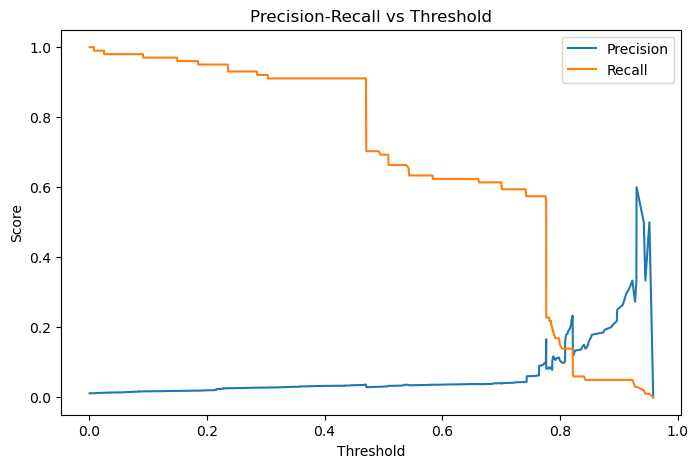

Threshold: 0.918 | Precision: 0.312 | Recall: 0.050


In [53]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

precisions, recalls, thresholds = precision_recall_curve(y4_test, y4_proba)

plt.figure(figsize=(8,5))
plt.plot(thresholds, precisions[:-1], label='Precision')
plt.plot(thresholds, recalls[:-1], label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.title('Precision-Recall vs Threshold')
plt.show()

# Find a threshold that gives a more usable precision (e.g. >=0.3) while keeping decent recall
for p, r, t in zip(precisions, recalls, thresholds):
    if p >= 0.3:
        print(f"Threshold: {t:.3f} | Precision: {p:.3f} | Recall: {r:.3f}")
        break

**The threshold chosen above (0.918) is a bad pick, despite technically satisfying "precision ≥ 0.3"** — it only catches 5% of true positives, and sits in a region past ~0.85 where the curve becomes wildly jagged. With only 101 positive test examples, extreme thresholds flag only a handful of tickets total, so a single prediction flipping right or wrong swings precision by 10–20 points — that instability is noise, not a real, reproducible operating point. The defensible choice lies in the stable "knee" region around 0.75–0.85 instead:

In [54]:
# Look specifically in the stable knee region, not the noisy tail
for p, r, t in zip(precisions, recalls, thresholds):
    if 0.75 <= t <= 0.85:
        print(f"Threshold: {t:.3f} | Precision: {p:.3f} | Recall: {r:.3f}")

Threshold: 0.752 | Precision: 0.060 | Recall: 0.574
Threshold: 0.753 | Precision: 0.060 | Recall: 0.574
Threshold: 0.753 | Precision: 0.060 | Recall: 0.574
Threshold: 0.755 | Precision: 0.061 | Recall: 0.574
Threshold: 0.757 | Precision: 0.061 | Recall: 0.574
Threshold: 0.758 | Precision: 0.061 | Recall: 0.574
Threshold: 0.759 | Precision: 0.061 | Recall: 0.574
Threshold: 0.760 | Precision: 0.062 | Recall: 0.574
Threshold: 0.761 | Precision: 0.062 | Recall: 0.574
Threshold: 0.763 | Precision: 0.062 | Recall: 0.574
Threshold: 0.764 | Precision: 0.062 | Recall: 0.574
Threshold: 0.764 | Precision: 0.062 | Recall: 0.574
Threshold: 0.764 | Precision: 0.090 | Recall: 0.574
Threshold: 0.766 | Precision: 0.090 | Recall: 0.574
Threshold: 0.766 | Precision: 0.090 | Recall: 0.574
Threshold: 0.768 | Precision: 0.090 | Recall: 0.574
Threshold: 0.768 | Precision: 0.090 | Recall: 0.574
Threshold: 0.768 | Precision: 0.091 | Recall: 0.574
Threshold: 0.769 | Precision: 0.092 | Recall: 0.574
Threshold: 0

### Task 4 — Two Candidate Operating Points

| | Threshold ≈ 0.774 | Threshold ≈ 0.821 |
|---|---|---|
| Precision | 0.097 | 0.233 |
| Recall | 0.574 | 0.139 |
| True positives caught | 58 of 101 | 14 of 101 |
| False alarm rate | ~90% | ~77% |
| Best suited for | Broad triage queue — costly to miss a real case, staff can quickly dismiss false positives | High-confidence alert / auto-escalation — trust in the signal matters more than catching every case |
| Main drawback | Alert fatigue risk from ~9 false alarms per real hit | Misses 86% of tickets that actually get linked to a change request |

Choosing between these is a **business decision** about which failure mode (false alarms vs. missed cases) costs ABC Tech more — not a modeling question with one correct answer.

### A gentler alternative: moderate class weighting

Rather than the full imbalance ratio (84.3), a moderate `scale_pos_weight=20` is also tried:

In [55]:
xgb4_moderate = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    scale_pos_weight=20,  # much gentler than 84.3
    max_depth=4,
    n_estimators=200,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1
)
xgb4_moderate.fit(X4_train, y4_train)
y4_proba_mod = xgb4_moderate.predict_proba(X4_test)[:, 1]
print("ROC-AUC (moderate weight):", roc_auc_score(y4_test, y4_proba_mod))

y4_pred_mod = (y4_proba_mod >= 0.5).astype(int)
print(classification_report(y4_test, y4_pred_mod, zero_division=0))

ROC-AUC (moderate weight): 0.8573626507424359
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      8945
           1       0.25      0.52      0.34       101

    accuracy                           0.98      9046
   macro avg       0.62      0.75      0.66      9046
weighted avg       0.99      0.98      0.98      9046



**This is a strong result on its own:** ROC-AUC is nearly identical (0.857 vs 0.854, confirming the same underlying signal), but at the **default 0.5 threshold** this model already achieves precision 0.25 / recall 0.52 (F1 0.34) — a far more usable balance out of the box than the full-weight model achieved even after manual threshold selection. **Lesson: aggressive class weighting isn't always better** — a moderate weight recovered most of the benefit with far less distortion, and without needing a hand-picked threshold at all.

## 8. Summary & Key Findings

| Task | Redefined Goal | Final Model | Headline Metric | Key Trade-off / Finding |
|---|---|---|---|---|
| 1. Priority Prediction | (as specified) | Random Forest (custom class weights) | 77% acc / 0.65 macro F1 | Best overall, but weakest recall (0.53) on the rarest, most urgent class — a Decision Tree or deep+balanced RF trades some accuracy for better recall (up to 0.63) |
| 2. Volume Forecasting | Scoped to reliable 26-week window, weekly grain | Holiday-aware naive | 207.2 MAE (vs 226.1 plain naive) | Flat series — sophistication (moving average, linear trend, exponential smoothing) actively hurt accuracy; a single targeted rule for the one known holiday anomaly was the winning approach |
| 3. CI Category Tagging | Predicts CI_Cat (no department field exists) | Tuned XGBoost | 0.35 macro F1 | Hyperparameter tuning produced **no improvement** over defaults — the bottleneck is available feature signal, not model choice |
| 4. Change-Request Linkage | Predicts change-request linkage (no RFC outcome field exists) | XGBoost (moderate class weight) | ROC-AUC 0.857 | Real signal despite 1.2% positive rate; deploying it requires an explicit business choice of operating threshold |

### Data Quality Issues Uncovered (worth highlighting in submission)

- **`Handle_Time_hrs` corruption:** decimal points silently dropped during export, then the fused digit strings were run through Indian-locale thousands-grouping — decoded and confirmed by reproducing the exact corrupted string from a hypothesized raw value, then replaced with a derived, verifiable version.
- **Hidden missingness:** placeholder strings (`"NS"`, `"NA"`) were masking true null rates in `.info()` output.
- **Structural zeros vs. true missingness:** blank values in count fields (`No_of_Related_Changes`, `No_of_Related_Incidents`) were verified — not assumed — to mean zero occurrences, based on the distribution of non-null values, before imputing.
- **Two leakage risks identified and avoided:** `Impact`/`Urgency` deterministically produce `Priority` (matrix relationship confirmed in the business case doc and in the data); `CI_Subcat` is a near-deterministic proxy for `CI_Cat` (98% purity).
- **Data collection ramp-up artifact:** the first ~19 months of ticket data reflect a pilot/test period, not real business volume, and were excluded from time-series forecasting.
- **Two under-populated classes merged:** Priority 1.0 (3 records) into Priority 2.0; CI_Cat's `applicationcomponent`/`Phone` (5 and 2 records) into `Other`.

### Overall Conclusion

Across all four redefined ITSM objectives, the project found genuine, explainable predictive signal in three of four tasks (Priority, CI Category, Change-Request Linkage) and confirmed that ticket volume itself is fundamentally stable and best modeled simply. Two of the four original business goals required honest rescoping once the actual database schema was inspected — a realistic outcome for applied ITSM analytics, and one that's documented transparently here rather than glossed over.